# Taller 2 · Modelos de clasificación

Sergio Perez

Samuel Charry

Este notebook sigue paso a paso las actividades 3, 4 y 5 de la Práctica 2 para entrenar y comparar modelos que predicen el abandono (churn). Parte de los conjuntos que genera la sección 2.1 del notebook principal del taller (churn_train.csv, churn_val.csv y churn_test.csv), así que ese notebook se ejecuta primero. Al final se eligen los dos modelos que se documentan en el notebook principal.

<a id='indice'></a>
# Índice

1. [Datos](#datos)
2. [Actividad 3 · Modelos de clasificación](#a3)
   - [Paso 1 · Escalado](#a3-p1)
   - [Paso 2 · Regresión logística](#a3-p2)
   - [Paso 3 · Árbol de decisión](#a3-p3)
   - [Paso 4 · KNN](#a3-p4)
   - [Paso 5 · Comparación en entrenamiento y validación](#a3-p5)
   - [Paso 6 · Curvas precisión-recall](#a3-p6)
   - [Paso 7 · Curvas ROC](#a3-p7)
   - [Paso 8 · Elección del mejor modelo](#a3-p8)
   - [Paso 9 · Evaluación en prueba](#a3-p9)
   - [Paso 10 · Conclusiones](#a3-p10)
3. [Actividad 4 · Ensambles](#a4)
   - [Paso 1 · Datos y modelos de partida](#a4-p1)
   - [Paso 2 · Random Forest](#a4-p2)
   - [Paso 3 · Gradient Boosting](#a4-p3)
   - [Paso 4 · Votación](#a4-p4)
   - [Paso 5 · Stacking](#a4-p5)
   - [Paso 6 · Comparación en entrenamiento y validación](#a4-p6)
   - [Paso 7 · Curvas precisión-recall](#a4-p7)
   - [Paso 8 · Curvas ROC](#a4-p8)
   - [Paso 9 · Elección del mejor ensamble](#a4-p9)
   - [Paso 10 · Evaluación en prueba](#a4-p10)
4. [Actividad 5 · Red neuronal](#a5)
   - [Paso 1 · Estandarización](#a5-p1)
   - [Paso 2 · Red densa](#a5-p2)
   - [Paso 3 · Tres arquitecturas](#a5-p3)
   - [Paso 4 · Evaluación de la mejor red](#a5-p4)
   - [Paso 5 · Comparación final en validación](#a5-p5)
   - [Paso 6 · Evaluación en prueba](#a5-p6)
   - [Paso 7 · Conclusiones](#a5-p7)
5. [Modelos seleccionados para el taller](#seleccion)

<a id='datos'></a>
# Datos

En esta sección:
- Se cargan los conjuntos de entrenamiento (6.000 registros), validación (2.000) y prueba (2.000), ya limpios, codificados e imputados.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
train = pd.read_csv("churn_train.csv")
val = pd.read_csv("churn_val.csv")
test = pd.read_csv("churn_test.csv")

X_train, y_train = train.drop(columns="churn"), train["churn"]
X_val, y_val = val.drop(columns="churn"), val["churn"]
X_test, y_test = test.drop(columns="churn"), test["churn"]

print(X_train.shape, X_val.shape, X_test.shape)
list(X_train.columns)

(6000, 10) (2000, 10) (2000, 10)


['age_clip',
 'balance',
 'credit_score_clip',
 'active_member',
 'country_Germany',
 'country_Spain',
 'gender_Male',
 'products_number_2',
 'products_number_3',
 'products_number_4']

<a id='a3'></a>
# Actividad 3 · Modelos de clasificación

> **Referencia:** [Práctica 2 · Actividad 3](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-2/actividad-3/)

En esta sección:
- Se optimizan regresión logística, árbol de decisión y KNN con GridSearchCV (5 folds estratificados, optimizando F1).
- En validación, el árbol (F1 0,556) y la regresión logística (0,551) quedan casi empatados; se elige la logística por ser más simple y sobreajustar menos.
- En prueba, la logística mantiene su desempeño (F1 0,568) y detecta el 76 % de los clientes que abandonan.

<a id='a3-p1'></a>
## Paso 1 · Escalado

Se estandarizan las variables continuas con StandardScaler ajustado solo con entrenamiento; las columnas 0/1 del one-hot se dejan igual. Los datos escalados se usan en todos los modelos; el conjunto de prueba solo se usa al final, con el modelo elegido.

In [3]:
from sklearn.preprocessing import StandardScaler

columnas_continuas = ["age_clip", "balance", "credit_score_clip"]
escalador = StandardScaler()

X_train_esc = X_train.copy()
X_val_esc = X_val.copy()
X_test_esc = X_test.copy()
X_train_esc[columnas_continuas] = escalador.fit_transform(X_train[columnas_continuas])   # solo con entrenamiento
X_val_esc[columnas_continuas] = escalador.transform(X_val[columnas_continuas])
X_test_esc[columnas_continuas] = escalador.transform(X_test[columnas_continuas])

X_train_esc[columnas_continuas].describe().loc[["mean", "std"]].round(2)

,age_clip,balance,credit_score_clip
mean,0.0,0.0,0.0
std,1.0,1.0,1.0


<a id='a3-p2'></a>
## Paso 2 · Regresión logística

GridSearchCV con validación cruzada estratificada de 5 folds, optimizando F1.

In [4]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, GridSearchCV

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

param_grid = {"C": [0.01, 0.1, 1, 10], "class_weight": [None, "balanced"]}
busqueda_logistica = GridSearchCV(LogisticRegression(max_iter=1000), param_grid, cv=kf, scoring="f1", n_jobs=-1)
busqueda_logistica.fit(X_train_esc, y_train)

print("Mejor combinación:", busqueda_logistica.best_params_)
print("F1 de validación cruzada:", round(busqueda_logistica.best_score_, 3))

Mejor combinación: {'C': 1, 'class_weight': 'balanced'}
F1 de validación cruzada: 0.567


- Mejor combinación: C = 1 y class_weight = "balanced" (F1 de validación cruzada 0,567).
- Se optimiza F1 y no exactitud porque solo el ~20 % de los clientes abandona: un modelo que nunca predice abandono ya tiene ~80 % de exactitud. F1 combina la precisión y el recall de la clase que interesa.

<a id='a3-p3'></a>
## Paso 3 · Árbol de decisión

In [5]:
from sklearn.tree import DecisionTreeClassifier

param_grid = {
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_leaf": [1, 5, 20, 50],
    "class_weight": [None, "balanced"],
}
busqueda_arbol = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=kf, scoring="f1", n_jobs=-1)
busqueda_arbol.fit(X_train_esc, y_train)

print("Mejor combinación:", busqueda_arbol.best_params_)
print("F1 de validación cruzada:", round(busqueda_arbol.best_score_, 3))

Mejor combinación: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 50}
F1 de validación cruzada: 0.576


- Mejor combinación: max_depth = 10, min_samples_leaf = 50 y class_weight = "balanced" (F1 0,576).
- La profundidad elegida es 10, pero lo que más limita al árbol es el mínimo de 50 registros por hoja: evita hojas que memorizan a unos pocos clientes.

<a id='a3-p4'></a>
## Paso 4 · KNN

In [6]:
from sklearn.neighbors import KNeighborsClassifier

param_grid = {"n_neighbors": [3, 5, 11, 21, 41], "weights": ["uniform", "distance"]}
busqueda_knn = GridSearchCV(KNeighborsClassifier(), param_grid, cv=kf, scoring="f1", n_jobs=-1)
busqueda_knn.fit(X_train_esc, y_train)

print("Mejor combinación:", busqueda_knn.best_params_)
print("F1 de validación cruzada:", round(busqueda_knn.best_score_, 3))

Mejor combinación: {'n_neighbors': 5, 'weights': 'distance'}
F1 de validación cruzada: 0.534


- Mejor combinación: n_neighbors = 5 y weights = "distance" (F1 0,534).
- KNN necesita variables escaladas porque decide por distancias: sin escalar, balance (de 0 a ~250.000) dominaría la distancia frente a age_clip (de 21 a 72) o las columnas 0/1.

<a id='a3-p5'></a>
## Paso 5 · Comparación en entrenamiento y validación

Funciones para no repetir el mismo código en cada actividad; también sirven para la red neuronal de la Actividad 5.

In [7]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, ConfusionMatrixDisplay)


def prediccion(modelo, X):
    """Clase predicha con umbral 0,5 (modelos de scikit-learn o redes de Keras)."""
    if hasattr(modelo, "layers"):
        return (modelo.predict(X, verbose=0).ravel() >= 0.5).astype(int)
    return modelo.predict(X)


def probabilidad(modelo, X):
    """Probabilidad de abandono (modelos de scikit-learn o redes de Keras)."""
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X)[:, 1]
    return modelo.predict(X, verbose=0).ravel()


def tabla_metricas(modelos, conjuntos):
    filas = []
    for titulo, X, y in conjuntos:
        for nombre, modelo in modelos.items():
            y_pred = prediccion(modelo, X)
            filas.append({
                "modelo": nombre,
                "conjunto": titulo,
                "exactitud": accuracy_score(y, y_pred),
                "precisión": precision_score(y, y_pred),
                "recall": recall_score(y, y_pred),
                "F1": f1_score(y, y_pred),
            })
    return pd.DataFrame(filas).round(3)


def tabla_validacion(modelos, X, y):
    filas = []
    for nombre, modelo in modelos.items():
        y_pred, y_prob = prediccion(modelo, X), probabilidad(modelo, X)
        filas.append({
            "modelo": nombre,
            "exactitud": accuracy_score(y, y_pred),
            "precisión": precision_score(y, y_pred),
            "recall": recall_score(y, y_pred),
            "F1": f1_score(y, y_pred),
            "AUC": roc_auc_score(y, y_prob),
            "AP": average_precision_score(y, y_prob),
        })
    return pd.DataFrame(filas).set_index("modelo").round(3).sort_values("F1", ascending=False)


def graficar_matrices(modelos, conjuntos):
    fig, axes = plt.subplots(len(conjuntos), len(modelos), squeeze=False,
                             figsize=(4.5 * len(modelos), 4 * len(conjuntos)))
    for fila, (titulo, X, y) in enumerate(conjuntos):
        for col, (nombre, modelo) in enumerate(modelos.items()):
            ConfusionMatrixDisplay.from_predictions(y, prediccion(modelo, X), ax=axes[fila, col], colorbar=False)
            axes[fila, col].set_title(f"{nombre} · {titulo}")
            axes[fila, col].grid(False)
    plt.tight_layout()
    plt.show()


def graficar_metricas(tabla):
    nombres = tabla["conjunto"].unique()
    fig, axes = plt.subplots(1, len(nombres), figsize=(7 * len(nombres), 4), sharey=True, squeeze=False)
    for ax, titulo in zip(axes[0], nombres):
        tabla[tabla["conjunto"] == titulo].set_index("modelo")[["exactitud", "precisión", "recall", "F1"]].plot(kind="bar", ax=ax, rot=0)
        ax.set_title(titulo)
    plt.tight_layout()
    plt.show()

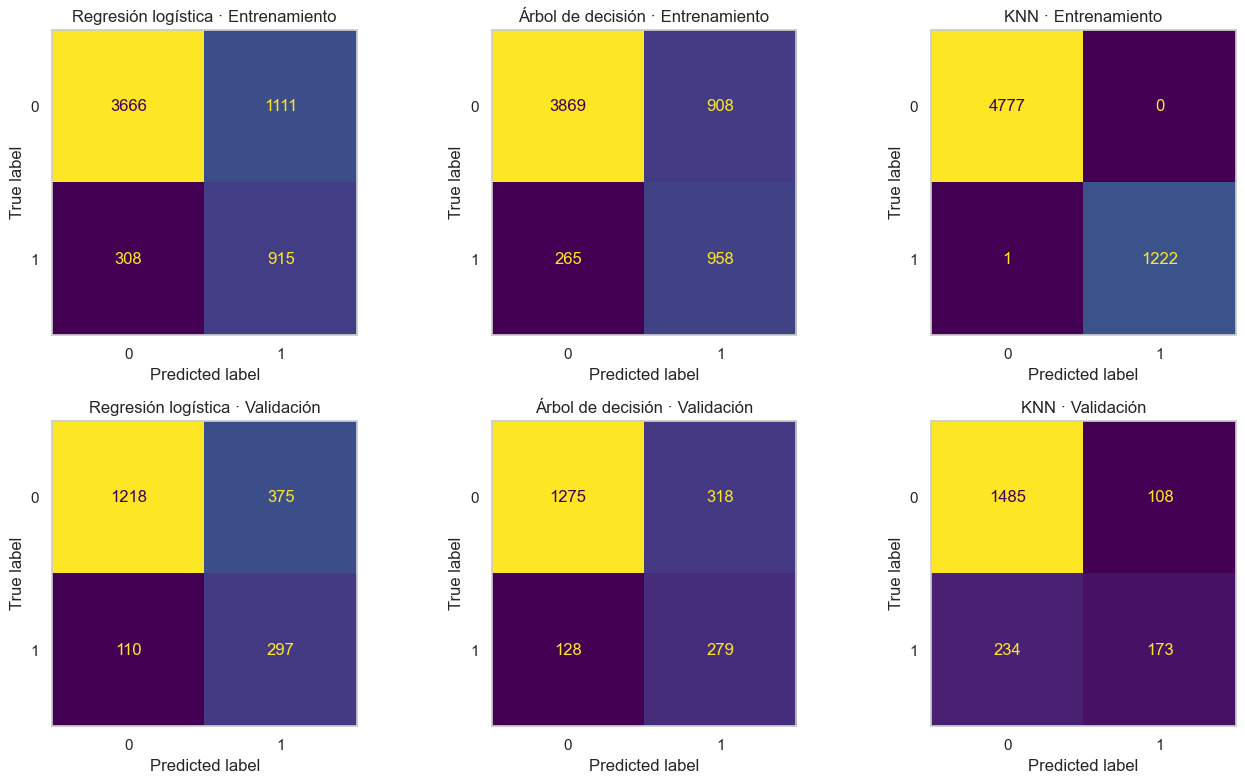

In [8]:
modelos_basicos = {
    "Regresión logística": busqueda_logistica.best_estimator_,
    "Árbol de decisión": busqueda_arbol.best_estimator_,
    "KNN": busqueda_knn.best_estimator_,
}
conjuntos = [("Entrenamiento", X_train_esc, y_train), ("Validación", X_val_esc, y_val)]

graficar_matrices(modelos_basicos, conjuntos)

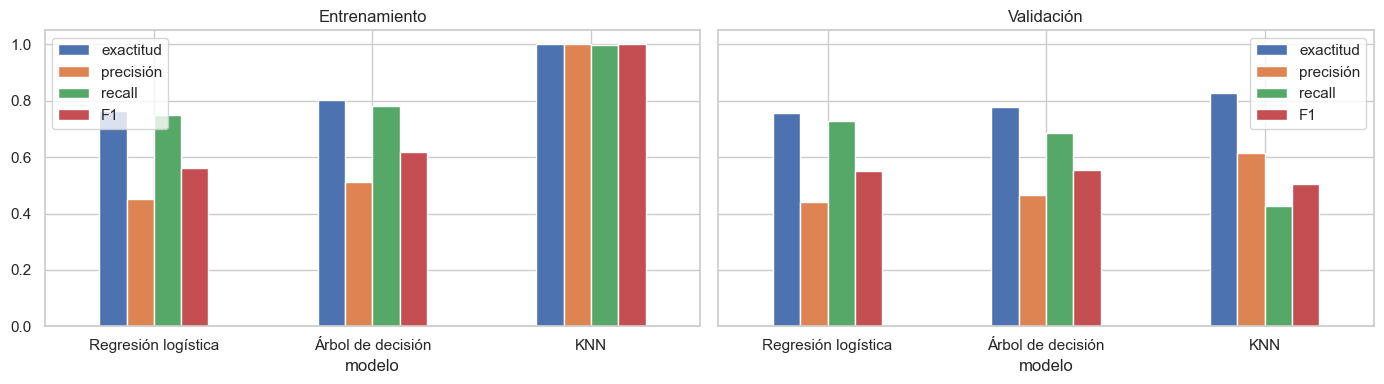

,modelo,conjunto,exactitud,precisión,recall,F1
0,Regresión logística,Entrenamiento,0.764,0.452,0.748,0.563
1,Árbol de decisión,Entrenamiento,0.804,0.513,0.783,0.620
2,KNN,Entrenamiento,1.000,1.000,0.999,1.000
3,Regresión logística,Validación,0.758,0.442,0.730,0.551
4,Árbol de decisión,Validación,0.777,0.467,0.686,0.556
5,KNN,Validación,0.829,0.616,0.425,0.503


In [9]:
tabla_basicos = tabla_metricas(modelos_basicos, conjuntos)
graficar_metricas(tabla_basicos)
tabla_basicos

Observaciones (validación, 407 clientes que abandonan)

- La regresión logística detecta 297 abandonos con 375 falsas alarmas; el árbol, 279 con 318; y KNN, 173 con 108.
- KNN es el de mayor diferencia entre entrenamiento y validación: su F1 baja de 1,000 a 0,503.
- Sus métricas de entrenamiento son perfectas porque, con weights = "distance", cada cliente de entrenamiento es su propio vecino a distancia 0 y decide su clase: el modelo memoriza el entrenamiento.

<a id='a3-p6'></a>
## Paso 6 · Curvas precisión-recall

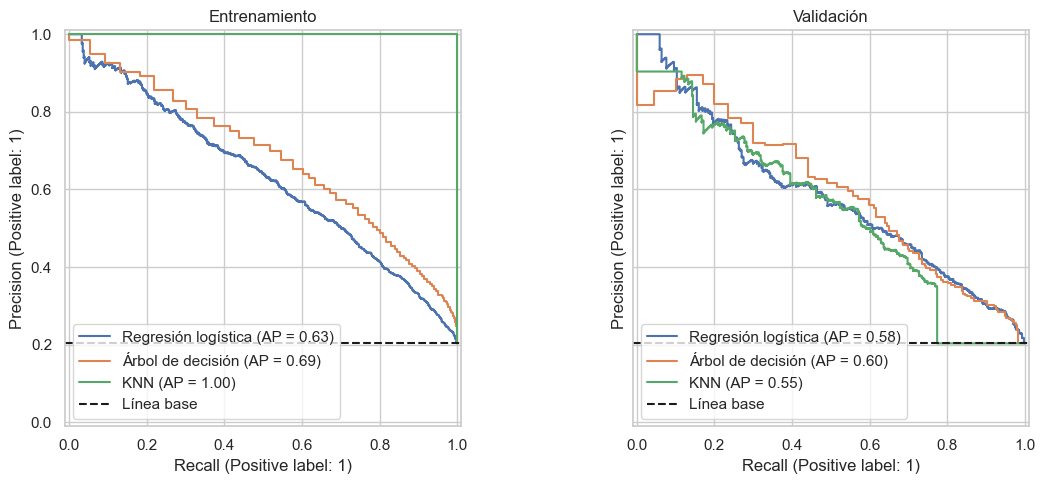

In [10]:
from sklearn.metrics import PrecisionRecallDisplay


def graficar_pr(modelos, conjuntos):
    fig, axes = plt.subplots(1, len(conjuntos), figsize=(6 * len(conjuntos), 5), sharey=True, squeeze=False)
    for ax, (titulo, X, y) in zip(axes[0], conjuntos):
        for nombre, modelo in modelos.items():
            PrecisionRecallDisplay.from_predictions(y, probabilidad(modelo, X), ax=ax, name=nombre)
        ax.axhline((y == 1).mean(), color="k", linestyle="--", label="Línea base")
        ax.set_title(titulo)
        ax.legend(loc="lower left")
    plt.tight_layout()
    plt.show()


graficar_pr(modelos_basicos, conjuntos)

- La línea base está en 0,204, la proporción de clientes que abandonan: es la precisión de un modelo al azar.
- En validación, el árbol tiene la mayor AP (0,599), seguido de la logística (0,583) y KNN (0,547). Los tres quedan muy por encima de la línea base.

<a id='a3-p7'></a>
## Paso 7 · Curvas ROC

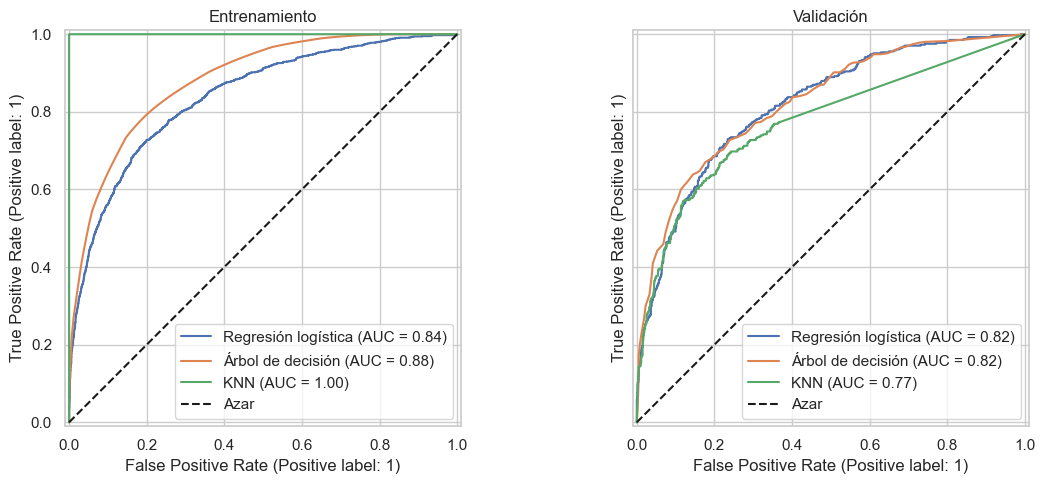

In [11]:
from sklearn.metrics import RocCurveDisplay


def graficar_roc(modelos, conjuntos):
    fig, axes = plt.subplots(1, len(conjuntos), figsize=(6 * len(conjuntos), 5), sharey=True, squeeze=False)
    for ax, (titulo, X, y) in zip(axes[0], conjuntos):
        for nombre, modelo in modelos.items():
            RocCurveDisplay.from_predictions(y, probabilidad(modelo, X), ax=ax, name=nombre)
        ax.plot([0, 1], [0, 1], "k--", label="Azar")
        ax.set_title(titulo)
        ax.legend(loc="lower right")
    plt.tight_layout()
    plt.show()


graficar_roc(modelos_basicos, conjuntos)

- En validación, el árbol tiene el mayor AUC (0,824), casi igual a la logística (0,818); KNN queda en 0,774.
- KNN es el que más cambia: su AUC baja de 1,00 en entrenamiento a 0,77 en validación.
- Las curvas ROC se ven más optimistas porque la tasa de falsos positivos se divide entre los ~1.600 clientes que no abandonan, así que muchas falsas alarmas apenas la mueven. La curva precisión-recall, en cambio, castiga cada falsa alarma frente a los pocos clientes que sí abandonan.

<a id='a3-p8'></a>
## Paso 8 · Elección del mejor modelo

In [12]:
tabla_val_basicos = tabla_validacion(modelos_basicos, X_val_esc, y_val)
tabla_val_basicos

,exactitud,precisión,recall,F1,AUC,AP
modelo,,,,,,
Árbol de decisión,0.777,0.467,0.686,0.556,0.824,0.599
Regresión logística,0.758,0.442,0.730,0.551,0.818,0.583
KNN,0.829,0.616,0.425,0.503,0.774,0.547


- El árbol tiene el F1 más alto (0,556), pero la regresión logística está prácticamente igual (0,551).
- Como son muy parecidos, se elige la regresión logística: es el modelo más simple y el que menos cambia entre entrenamiento y validación (F1 de 0,563 a 0,551, frente a 0,620 a 0,556 del árbol).
- Si no detectar a un cliente que abandona fuera más costoso que contactar a uno que no iba a abandonar, la elección no cambia: la logística también tiene el mayor recall (0,730).

<a id='a3-p9'></a>
## Paso 9 · Evaluación en prueba

Se evalúa la regresión logística, el modelo elegido en el paso 8.

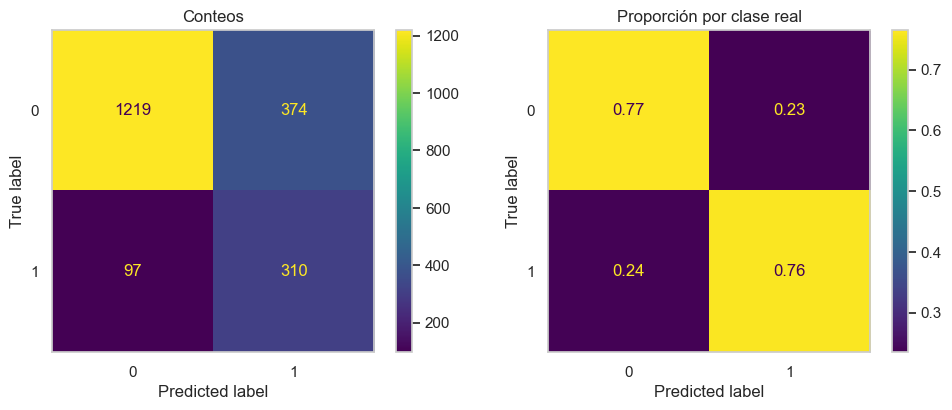

In [13]:
nombre_basico = "Regresión logística"
mejor_basico = modelos_basicos[nombre_basico]
y_pred = mejor_basico.predict(X_test_esc)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[0])
axes[0].set_title("Conteos")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true", ax=axes[1])
axes[1].set_title("Proporción por clase real")
for ax in axes:
    ax.grid(False)
plt.tight_layout()
plt.show()

In [14]:
conjuntos_prueba = [("Validación", X_val_esc, y_val), ("Prueba", X_test_esc, y_test)]
display(tabla_metricas({nombre_basico: mejor_basico}, conjuntos_prueba))

linea_base = y_test.value_counts(normalize=True).max()   # modelo que siempre predice "no abandona"
print(f"Exactitud de la línea base en prueba: {linea_base:.3f}")

,modelo,conjunto,exactitud,precisión,recall,F1
0,Regresión logística,Validación,0.758,0.442,0.730,0.551
1,Regresión logística,Prueba,0.764,0.453,0.762,0.568


Exactitud de la línea base en prueba: 0.796


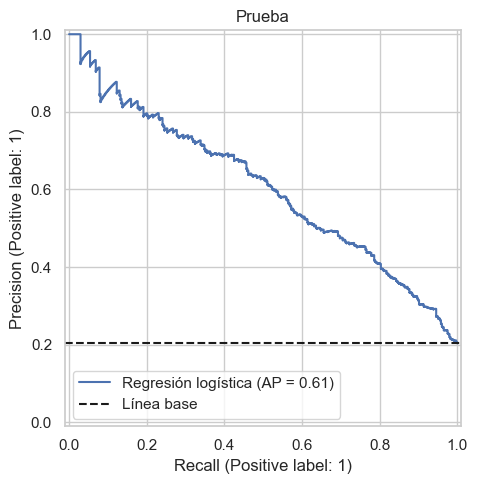

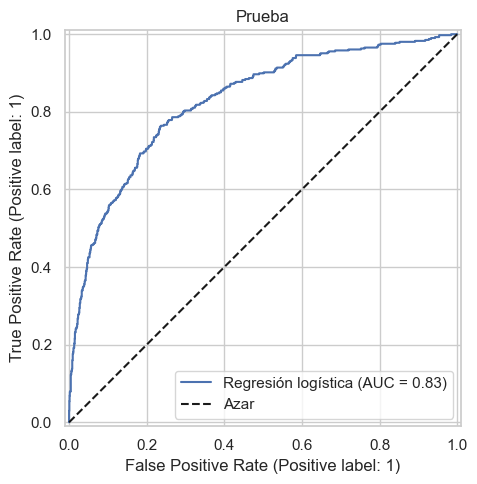

In [15]:
prueba = [("Prueba", X_test_esc, y_test)]
graficar_pr({nombre_basico: mejor_basico}, prueba)
graficar_roc({nombre_basico: mejor_basico}, prueba)

- En prueba, la logística detecta 310 de los 407 clientes que abandonan (76 %), con 374 falsas alarmas.
- Las métricas se mantienen e incluso mejoran un poco respecto a validación (F1 de 0,551 a 0,568), así que el modelo generaliza.
- Su exactitud (0,764) es menor que la de la línea base que siempre predice "no abandona" (0,796), pero esa línea base no detecta a ningún cliente que abandona. Por eso la exactitud sola no basta con clases desbalanceadas: premia acertar la clase mayoritaria e ignora la que interesa.

<a id='a3-p10'></a>
## Paso 10 · Conclusiones

Coeficientes de la regresión logística (las variables continuas están estandarizadas) y efecto del umbral de decisión en validación.

Intercepto: [0.67739962]


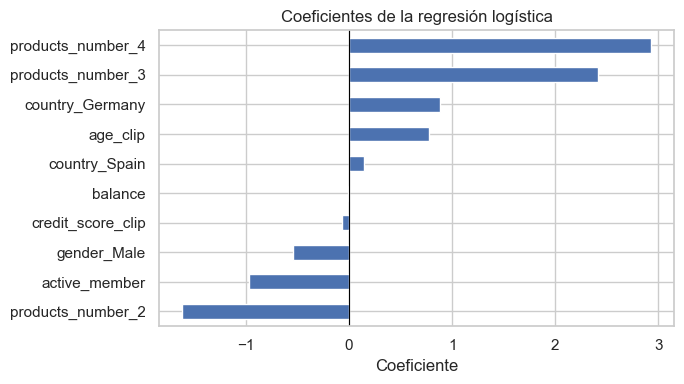

products_number_2   -1.62
active_member       -0.97
gender_Male         -0.54
credit_score_clip   -0.06
balance             -0.01
country_Spain        0.15
age_clip             0.77
country_Germany      0.88
products_number_3    2.41
products_number_4    2.93
dtype: float64


In [16]:
print("Intercepto:", mejor_basico.intercept_)
coef = pd.Series(mejor_basico.coef_[0], index=X_train.columns).sort_values()

coef.plot.barh(figsize=(7, 4))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coeficiente")
plt.title("Coeficientes de la regresión logística")
plt.tight_layout()
plt.show()
print(coef.round(2))

In [17]:
y_prob = mejor_basico.predict_proba(X_val_esc)[:, 1]

filas = []
for umbral in [0.3, 0.4, 0.5, 0.6, 0.7]:
    y_pred = (y_prob >= umbral).astype(int)
    filas.append({
        "umbral": umbral,
        "clientes contactados": y_pred.sum(),
        "abandonos detectados": ((y_pred == 1) & (y_val == 1)).sum(),
        "precisión": precision_score(y_val, y_pred),
        "recall": recall_score(y_val, y_pred),
    })
pd.DataFrame(filas).round(3)

,umbral,clientes contactados,abandonos detectados,precisión,recall
0,0.3,1079,354,0.328,0.870
1,0.4,853,323,0.379,0.794
2,0.5,672,297,0.442,0.730
3,0.6,498,248,0.498,0.609
4,0.7,348,200,0.575,0.491


- Variables que más explican el abandono (las continuas están estandarizadas): tener 3 o 4 productos (coeficientes ≈ 2,4 y 2,9), ser de Alemania (≈ 0,9) y la edad (≈ 0,8 por desviación estándar) aumentan el riesgo; tener 2 productos (≈ -1,6), ser miembro activo (≈ -1,0) y ser hombre (≈ -0,5) lo reducen. balance y credit_score_clip casi no pesan.
- El error más frecuente son las falsas alarmas (375 en validación frente a 110 abandonos no detectados), por el class_weight = "balanced".
- Para detectar más abandonos se puede bajar el umbral: con 0,3 se detecta el 87 % (354 de 407), pero se contactan 1.079 clientes y solo el 33 % de ellos iba a abandonar. El costo es pagar por más contactos que no lo necesitaban.

<a id='a4'></a>
# Actividad 4 · Ensambles

> **Referencia:** [Práctica 2 · Actividad 4](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-2/actividad-4/)

En esta sección:
- Se entrenan Random Forest, Gradient Boosting, votación y stacking a partir de los modelos de la Actividad 3.
- Random Forest es el mejor ensamble: F1 0,585 en validación y 0,613 en prueba, por encima de la regresión logística.

<a id='a4-p1'></a>
## Paso 1 · Datos y modelos de partida

Se reutilizan los datos escalados y los tres modelos optimizados de la Actividad 3. La prueba solo se usa al final, con el ensamble elegido.

<a id='a4-p2'></a>
## Paso 2 · Random Forest

In [18]:
from sklearn.ensemble import RandomForestClassifier

param_grid = {
    "n_estimators": [200, 400],
    "max_depth": [5, 10, None],
    "min_samples_leaf": [1, 5, 20],
    "class_weight": [None, "balanced"],
}
busqueda_rf = GridSearchCV(RandomForestClassifier(random_state=42), param_grid, cv=kf, scoring="f1", n_jobs=-1)
busqueda_rf.fit(X_train_esc, y_train)

print("Mejor combinación:", busqueda_rf.best_params_)
print("F1 de validación cruzada:", round(busqueda_rf.best_score_, 3))

Mejor combinación: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 200}
F1 de validación cruzada: 0.624


- Mejor combinación: 200 árboles, max_depth = 10, min_samples_leaf = 5 y class_weight = "balanced" (F1 de validación cruzada 0,624).

<a id='a4-p3'></a>
## Paso 3 · Gradient Boosting

No acepta class_weight, así que se usan pesos balanceados por registro.

In [19]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.utils.class_weight import compute_sample_weight

pesos = compute_sample_weight("balanced", y_train)

param_grid = {"n_estimators": [100, 300], "learning_rate": [0.05, 0.1], "max_depth": [2, 3, 4]}
busqueda_gb = GridSearchCV(GradientBoostingClassifier(random_state=42), param_grid, cv=kf, scoring="f1", n_jobs=-1)
busqueda_gb.fit(X_train_esc, y_train, sample_weight=pesos)

print("Mejor combinación:", busqueda_gb.best_params_)
print("F1 de validación cruzada (ponderado con los pesos):", round(busqueda_gb.best_score_, 3))

Mejor combinación: {'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 100}
F1 de validación cruzada (ponderado con los pesos): 0.779


- Mejor combinación: learning_rate = 0,05, max_depth = 4 y 100 árboles.
- Su F1 de validación cruzada (0,779) no es comparable con el de los otros modelos: GridSearchCV también pondera la métrica con los pesos balanceados, que dan más importancia a los aciertos en la clase minoritaria. Por eso los modelos se comparan en validación.
- learning_rate y n_estimators se compensan: con una tasa más baja cada árbol corrige menos el error de los anteriores, así que se necesitan más árboles para el mismo ajuste. Aquí ganó la combinación menos agresiva (tasa 0,05 con 100 árboles).

<a id='a4-p4'></a>
## Paso 4 · Votación

In [20]:
from sklearn.ensemble import VotingClassifier

modelos_base = [
    ("logistica", busqueda_logistica.best_estimator_),
    ("arbol", busqueda_arbol.best_estimator_),
    ("knn", busqueda_knn.best_estimator_),
]

votacion_dura = VotingClassifier(estimators=modelos_base, voting="hard")
votacion_dura.fit(X_train_esc, y_train)

votacion_suave = VotingClassifier(estimators=modelos_base, voting="soft")
votacion_suave.fit(X_train_esc, y_train)

tabla_metricas({"Votación dura": votacion_dura, "Votación suave": votacion_suave}, [("Validación", X_val_esc, y_val)])

,modelo,conjunto,exactitud,precisión,recall,F1
0,Votación dura,Validación,0.806,0.519,0.649,0.576
1,Votación suave,Validación,0.820,0.552,0.622,0.585


- La votación suave tiene mayor F1 en validación (0,585) que la dura (0,576): promedia las probabilidades y tiene en cuenta qué tan seguro está cada modelo, mientras que la dura solo cuenta votos.
- Combinar sí ayuda: la votación suave supera a cada modelo por separado (0,551, 0,556 y 0,503). Se conserva la votación suave para los siguientes pasos.

<a id='a4-p5'></a>
## Paso 5 · Stacking

In [21]:
from sklearn.ensemble import StackingClassifier

stacking = StackingClassifier(estimators=modelos_base, final_estimator=LogisticRegression(),
                              cv=5, stack_method="predict_proba")
param_grid = {"final_estimator__C": [0.1, 1, 10], "final_estimator__class_weight": [None, "balanced"]}
busqueda_stacking = GridSearchCV(stacking, param_grid, cv=kf, scoring="f1", n_jobs=-1)
busqueda_stacking.fit(X_train_esc, y_train)

print("Mejor combinación:", busqueda_stacking.best_params_)
print("F1 de validación cruzada:", round(busqueda_stacking.best_score_, 3))
print("Peso de cada modelo base (logística, árbol, KNN):", busqueda_stacking.best_estimator_.final_estimator_.coef_.round(2))

Mejor combinación: {'final_estimator__C': 0.1, 'final_estimator__class_weight': 'balanced'}
F1 de validación cruzada: 0.591
Peso de cada modelo base (logística, árbol, KNN): [[2.03 2.12 1.33]]


- Mejor combinación del modelo final: C = 0,1 y class_weight = "balanced" (F1 0,591). Le da pesos parecidos a la logística (2,03) y al árbol (2,12), y menos a KNN (1,33).
- Los modelos base deben ser distintos para que se equivoquen en clientes diferentes; si cometieran los mismos errores, combinarlos no aportaría nada. Aquí se combinan un modelo lineal, uno de árboles y uno de distancias.

<a id='a4-p6'></a>
## Paso 6 · Comparación en entrenamiento y validación

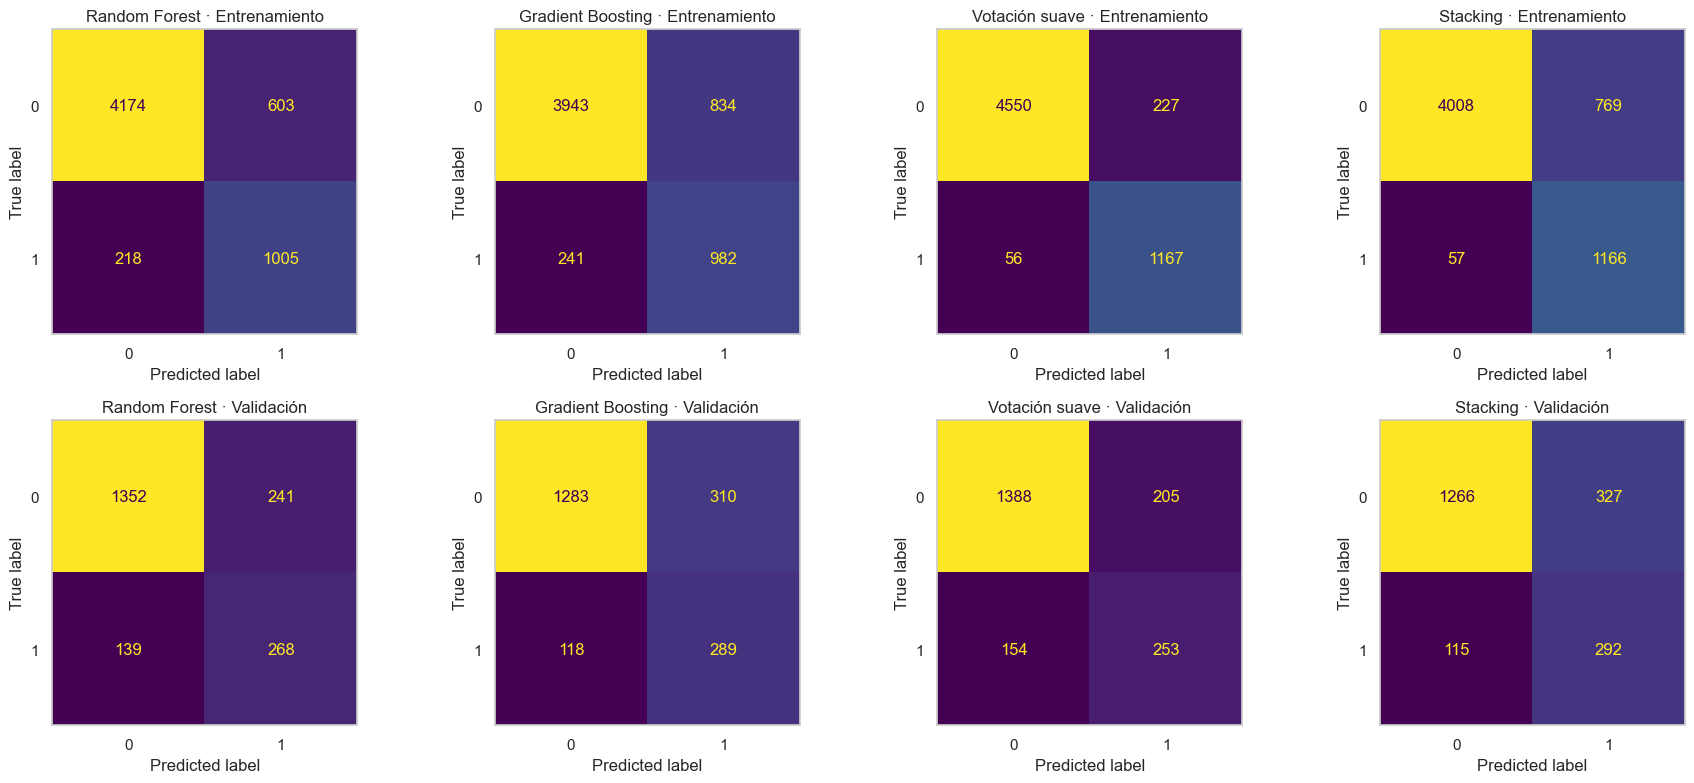

In [22]:
ensambles = {
    "Random Forest": busqueda_rf.best_estimator_,
    "Gradient Boosting": busqueda_gb.best_estimator_,
    "Votación suave": votacion_suave,
    "Stacking": busqueda_stacking.best_estimator_,
}
graficar_matrices(ensambles, conjuntos)

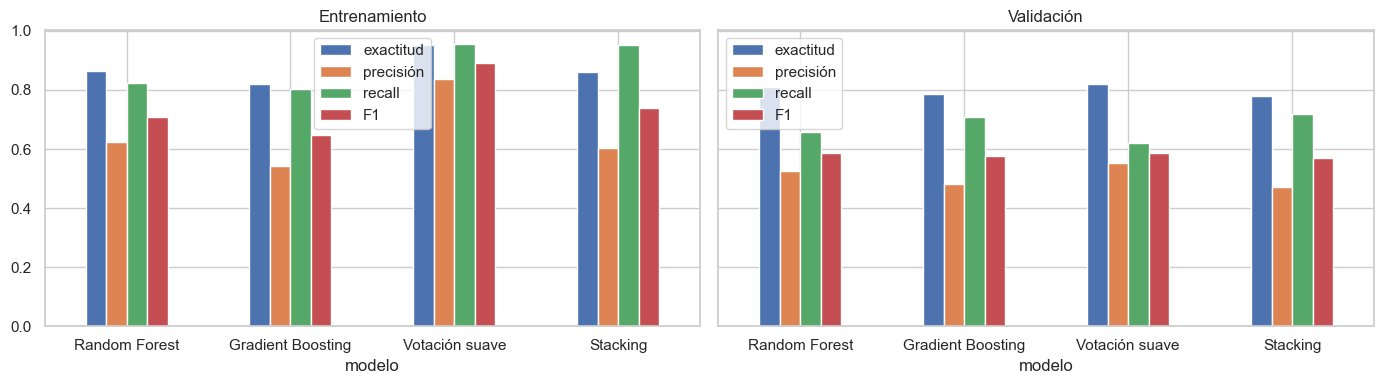

,modelo,conjunto,exactitud,precisión,recall,F1
0,Random Forest,Entrenamiento,0.863,0.625,0.822,0.710
1,Gradient Boosting,Entrenamiento,0.821,0.541,0.803,0.646
2,Votación suave,Entrenamiento,0.953,0.837,0.954,0.892
3,Stacking,Entrenamiento,0.862,0.603,0.953,0.738
4,Random Forest,Validación,0.810,0.527,0.658,0.585
5,Gradient Boosting,Validación,0.786,0.482,0.710,0.575
6,Votación suave,Validación,0.820,0.552,0.622,0.585
7,Stacking,Validación,0.779,0.472,0.717,0.569


In [23]:
tabla_ensambles = tabla_metricas(ensambles, conjuntos)
graficar_metricas(tabla_ensambles)
tabla_ensambles

Observaciones (validación, 407 clientes que abandonan)

- Random Forest detecta 268 abandonos con 241 falsas alarmas; Gradient Boosting, 289 con 310; la votación suave, 253 con 205; y stacking, 292 con 327.
- La votación suave es la que más sobreajusta (F1 de 0,892 en entrenamiento a 0,585 en validación), porque hereda la memorización de KNN. Stacking también tiene una brecha grande (0,738 a 0,569).

<a id='a4-p7'></a>
## Paso 7 · Curvas precisión-recall

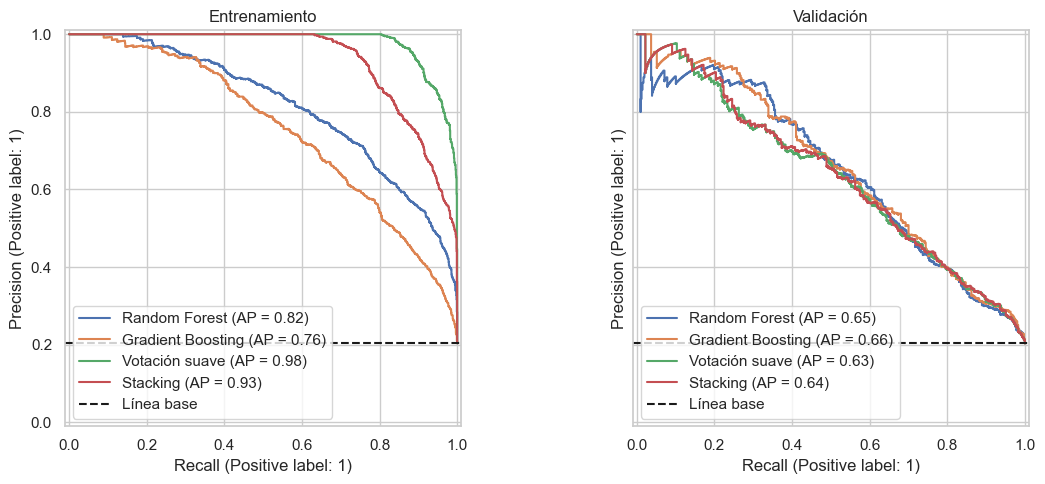

In [24]:
graficar_pr(ensambles, conjuntos)

- En validación, Gradient Boosting tiene la mayor AP (0,657), seguido de Random Forest (0,645), stacking (0,636) y la votación suave (0,633). Las diferencias son pequeñas.

<a id='a4-p8'></a>
## Paso 8 · Curvas ROC

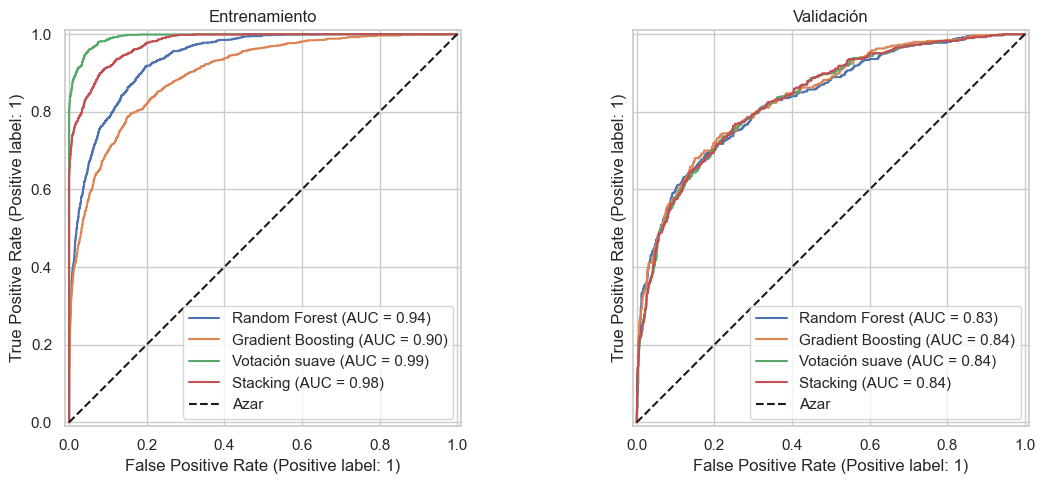

In [25]:
graficar_roc(ensambles, conjuntos)

- En validación, Gradient Boosting tiene el mayor AUC (0,841), pero los cuatro están entre 0,835 y 0,841 y las curvas casi se superponen. En entrenamiento sí se separan, otra señal del sobreajuste de la votación y el stacking.

<a id='a4-p9'></a>
## Paso 9 · Elección del mejor ensamble

Tabla en validación de los cuatro ensambles y del mejor modelo de la Actividad 3.

In [26]:
tabla_val_ensambles = tabla_validacion({**ensambles, f"{nombre_basico} (Actividad 3)": mejor_basico}, X_val_esc, y_val)
tabla_val_ensambles

,exactitud,precisión,recall,F1,AUC,AP
modelo,,,,,,
Random Forest,0.810,0.527,0.658,0.585,0.835,0.645
Votación suave,0.820,0.552,0.622,0.585,0.835,0.633
Gradient Boosting,0.786,0.482,0.710,0.575,0.841,0.657
Stacking,0.779,0.472,0.717,0.569,0.837,0.636
Regresión logística (Actividad 3),0.758,0.442,0.730,0.551,0.818,0.583


- Random Forest y la votación suave empatan en F1 (0,585). Se elige Random Forest porque sobreajusta mucho menos (F1 de entrenamiento 0,710 frente a 0,892) y es un solo modelo, no la combinación de tres.
- Los ensambles sí mejoran al mejor modelo básico: Random Forest sube el F1 de 0,551 a 0,585 y la AP de 0,583 a 0,645.
- La mejora justifica el costo: con 6.000 registros, Random Forest se entrena en segundos. Lo que se pierde es interpretabilidad, porque ya no hay coeficientes que leer directamente.

<a id='a4-p10'></a>
## Paso 10 · Evaluación en prueba

Se evalúa Random Forest, el ensamble elegido en el paso 9, y se compara con la regresión logística.

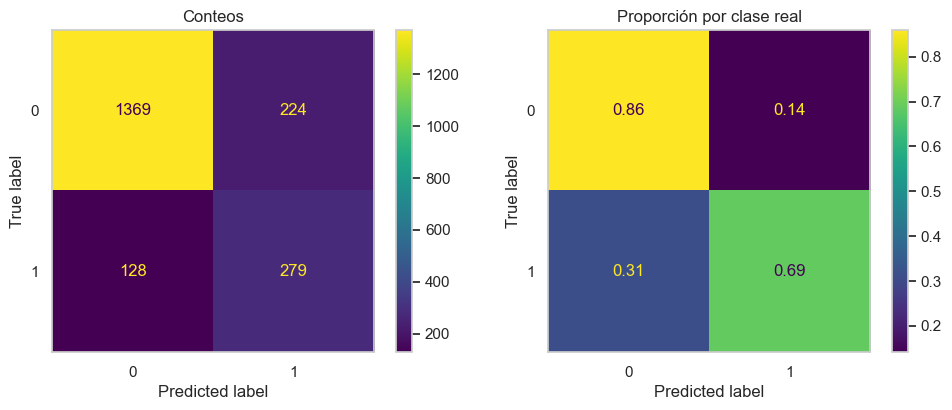

In [27]:
nombre_ensamble = "Random Forest"
mejor_ensamble = ensambles[nombre_ensamble]
y_pred = mejor_ensamble.predict(X_test_esc)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[0])
axes[0].set_title("Conteos")
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, normalize="true", ax=axes[1])
axes[1].set_title("Proporción por clase real")
for ax in axes:
    ax.grid(False)
plt.tight_layout()
plt.show()

In [28]:
tabla_metricas({nombre_ensamble: mejor_ensamble, nombre_basico: mejor_basico}, conjuntos_prueba)

,modelo,conjunto,exactitud,precisión,recall,F1
0,Random Forest,Validación,0.810,0.527,0.658,0.585
1,Regresión logística,Validación,0.758,0.442,0.730,0.551
2,Random Forest,Prueba,0.824,0.555,0.686,0.613
3,Regresión logística,Prueba,0.764,0.453,0.762,0.568


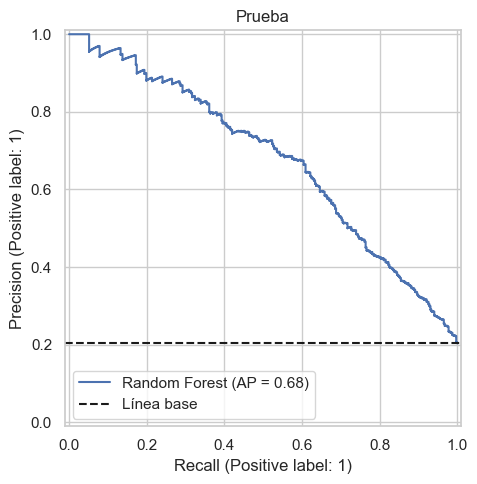

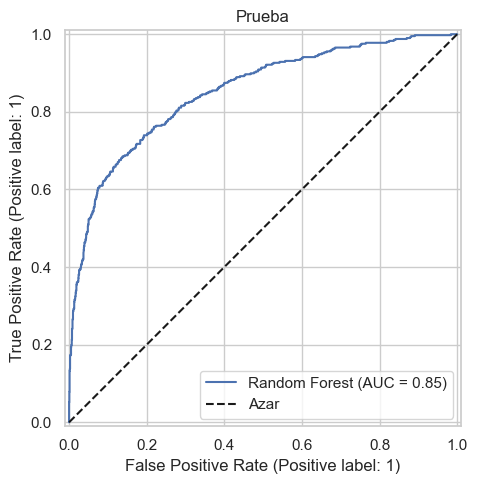

In [29]:
graficar_pr({nombre_ensamble: mejor_ensamble}, prueba)
graficar_roc({nombre_ensamble: mejor_ensamble}, prueba)

- En prueba, Random Forest detecta 279 de los 407 clientes que abandonan (69 %), con 224 falsas alarmas.
- Las métricas se mantienen y mejoran un poco respecto a validación (F1 de 0,585 a 0,613).
- Frente a la regresión logística en prueba, Random Forest tiene mejor F1 (0,613 frente a 0,568) y precisión (0,555 frente a 0,453), pero menor recall (0,686 frente a 0,762): detecta algo menos de abandonos con muchas menos falsas alarmas.

<a id='a5'></a>
# Actividad 5 · Red neuronal

> **Referencia:** [Práctica 2 · Actividad 5](https://datascience-uniandes.github.io/PracticasMachineLearning/talleres/practica-2/actividad-5/)

En esta sección:
- La mejor red (tres capas de 32, 16 y 8 neuronas) tiene F1 0,559 en validación: mucha precisión pero poco recall.
- En la comparación final entre la regresión logística, Random Forest y la red, gana Random Forest.

<a id='a5-p1'></a>
## Paso 1 · Estandarización

Se reutilizan X_train_esc, X_val_esc y X_test_esc: las variables continuas ya están estandarizadas con StandardScaler ajustado solo con entrenamiento. La prueba solo se usa al final.

<a id='a5-p2'></a>
## Paso 2 · Red densa

Dos capas ocultas de 16 y 8 neuronas con ReLU y una neurona de salida con sigmoide.

In [30]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"   # oculta mensajes informativos de TensorFlow

import keras
from keras import layers

keras.utils.set_random_seed(42)

model = keras.Sequential([
    keras.Input(shape=(X_train_esc.shape[1],)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid"),
])
model.compile(optimizer="adam", loss="binary_crossentropy")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           176 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 321 (1.25 KB)

 Trainable params: 321 (1.25 KB)

 Non-trainable params: 0 (0.00 B)

- La red tiene 321 parámetros: 176 en la primera capa (10 entradas × 16 + 16 sesgos), 136 en la segunda (16 × 8 + 8) y 9 en la salida (8 × 1 + 1).
- La salida usa sigmoide porque devuelve un valor entre 0 y 1, que se interpreta como la probabilidad de abandono.

<a id='a5-p3'></a>
## Paso 3 · Tres arquitecturas

100 épocas, lotes de 32 y Dropout(0.2) después de cada capa oculta.

In [31]:
def crear_red(capas):
    """Red densa con Dropout(0.2) después de cada capa oculta."""
    keras.utils.set_random_seed(42)
    model = keras.Sequential([keras.Input(shape=(X_train_esc.shape[1],))])
    for neuronas in capas:
        model.add(layers.Dense(neuronas, activation="relu"))
        model.add(layers.Dropout(0.2))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(
        optimizer="adam",
        loss="binary_crossentropy",
        metrics=[keras.metrics.AUC(name="auc"), keras.metrics.Recall(name="recall")],
    )
    return model


arquitecturas = {"Red 8": [8], "Red 16-8": [16, 8], "Red 32-16-8": [32, 16, 8]}
redes = {}
for nombre, capas in arquitecturas.items():
    redes[nombre] = crear_red(capas)
    redes[nombre].fit(
        X_train_esc, y_train,
        validation_data=(X_val_esc, y_val),
        epochs=100,
        batch_size=32,
        verbose=0,
    )

tabla_metricas(redes, conjuntos)

,modelo,conjunto,exactitud,precisión,recall,F1
0,Red 8,Entrenamiento,0.861,0.776,0.446,0.566
1,Red 16-8,Entrenamiento,0.866,0.788,0.469,0.588
2,Red 32-16-8,Entrenamiento,0.878,0.832,0.500,0.624
3,Red 8,Validación,0.847,0.724,0.400,0.516
4,Red 16-8,Validación,0.858,0.763,0.435,0.554
5,Red 32-16-8,Validación,0.860,0.774,0.437,0.559


- La red de tres capas (32-16-8) tiene el mayor F1 en validación (0,559), apenas por encima de la de dos capas (0,554); la de una capa queda en 0,516.
- Una red más grande no siempre es mejor: pasar de 16-8 a 32-16-8 casi no mejora en validación, pero sí aumenta la diferencia con entrenamiento (F1 de 0,624 frente a 0,559).

<a id='a5-p4'></a>
## Paso 4 · Evaluación de la mejor red

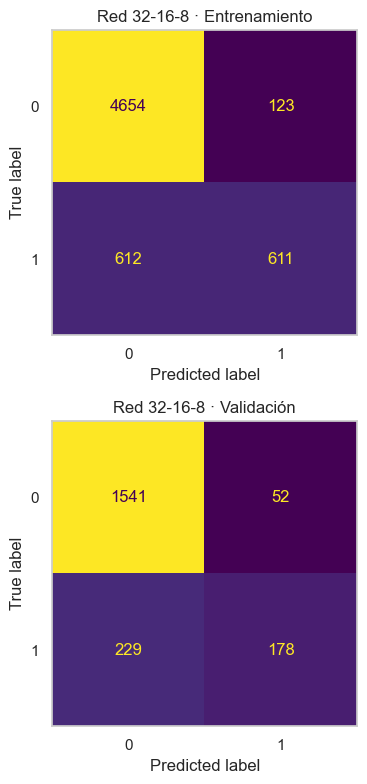

In [32]:
nombre_red = "Red 32-16-8"
mejor_red = redes[nombre_red]

graficar_matrices({nombre_red: mejor_red}, conjuntos)

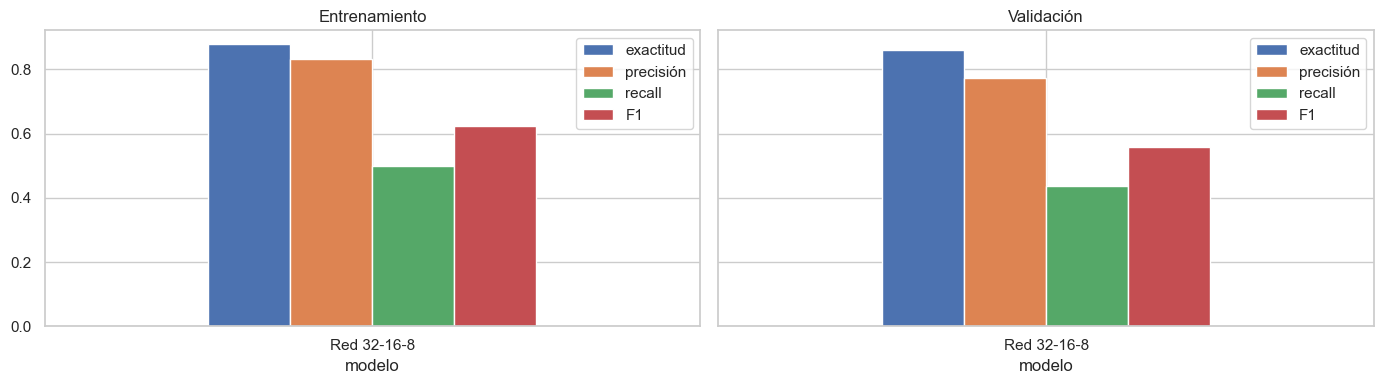

,modelo,conjunto,exactitud,precisión,recall,F1
0,Red 32-16-8,Entrenamiento,0.878,0.832,0.500,0.624
1,Red 32-16-8,Validación,0.860,0.774,0.437,0.559


In [33]:
tabla_red = tabla_metricas({nombre_red: mejor_red}, conjuntos)
graficar_metricas(tabla_red)
tabla_red

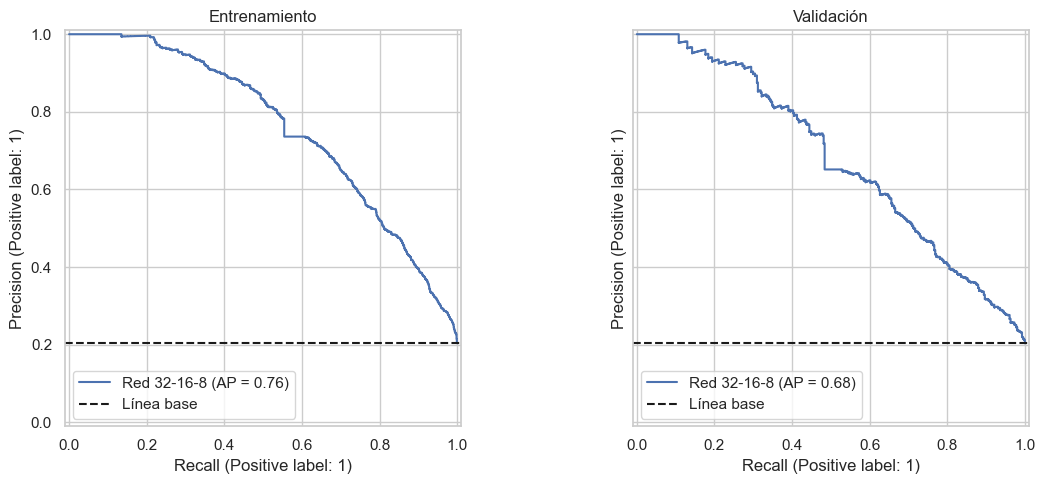

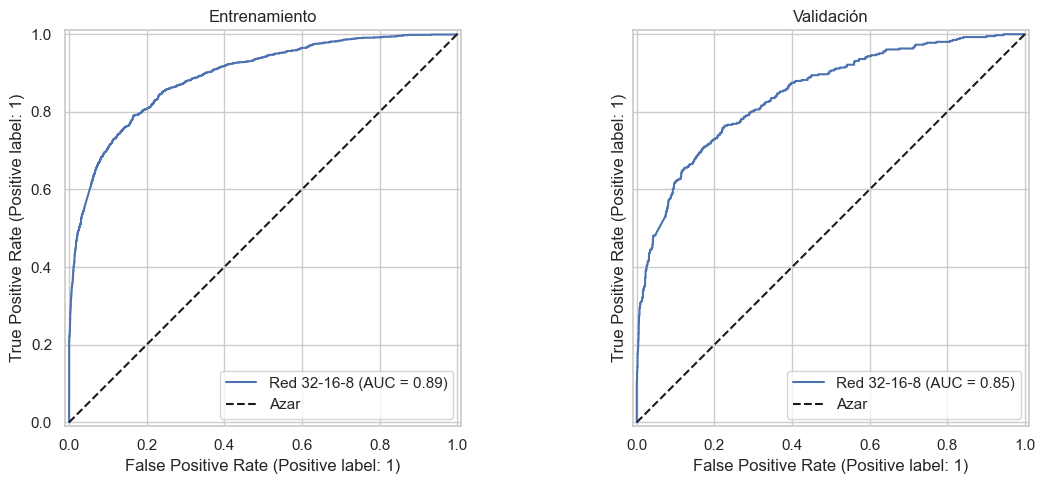

In [34]:
graficar_pr({nombre_red: mejor_red}, conjuntos)
graficar_roc({nombre_red: mejor_red}, conjuntos)

- En validación, la red detecta solo 178 de los 407 clientes que abandonan (recall 0,437), pero casi sin falsas alarmas (52; precisión 0,774).
- Esto pasa porque, a diferencia de los otros modelos, la red se entrena sin pesos por clase: con el umbral de 0,5 predice abandono solo cuando está muy segura.
- Aun así, ordena bien a los clientes: su AP en validación (0,678) es la más alta de todos los modelos. Con un umbral más bajo detectaría más abandonos.

<a id='a5-p5'></a>
## Paso 5 · Comparación final en validación

El mejor modelo básico, el mejor ensamble y la mejor red.

,exactitud,precisión,recall,F1,AUC,AP
modelo,,,,,,
Random Forest,0.810,0.527,0.658,0.585,0.835,0.645
Red 32-16-8,0.860,0.774,0.437,0.559,0.847,0.678
Regresión logística,0.758,0.442,0.730,0.551,0.818,0.583


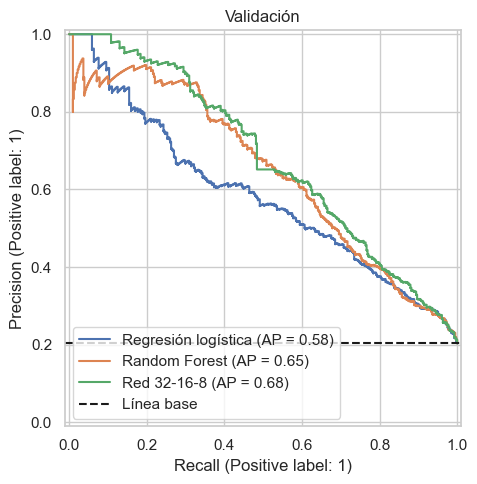

In [35]:
finalistas = {nombre_basico: mejor_basico, nombre_ensamble: mejor_ensamble, nombre_red: mejor_red}

tabla_final = tabla_validacion(finalistas, X_val_esc, y_val)
display(tabla_final)
graficar_pr(finalistas, [("Validación", X_val_esc, y_val)])

- Random Forest tiene el mayor F1 en validación (0,585) y es el modelo final.
- Ventajas: el mejor equilibrio entre precisión (0,527) y recall (0,658). Desventajas: es menos interpretable que la regresión logística y ordena a los clientes peor que la red (AP 0,645 frente a 0,678).
- La red tiene la mejor AP y el mejor AUC, pero con el umbral de 0,5 deja escapar a la mayoría de los clientes que abandonan. La regresión logística es la más fácil de explicar y la que más abandonos detecta (recall 0,730), a cambio de más falsas alarmas.

<a id='a5-p6'></a>
## Paso 6 · Evaluación en prueba

In [36]:
pd.concat({
    "Validación": tabla_final,
    "Prueba": tabla_validacion(finalistas, X_test_esc, y_test),
})

exactitud  precisión  recall     F1    AUC  \
           modelo                                                            
Validación Random Forest            0.810      0.527   0.658  0.585  0.835   
           Red 32-16-8              0.860      0.774   0.437  0.559  0.847   
           Regresión logística      0.758      0.442   0.730  0.551  0.818   
Prueba     Random Forest            0.824      0.555   0.686  0.613  0.851   
           Regresión logística      0.764      0.453   0.762  0.568  0.828   
           Red 32-16-8              0.856      0.763   0.420  0.542  0.856   

                                   AP  
           modelo                      
Validación Random Forest        0.645  
           Red 32-16-8          0.678  
           Regresión logística  0.583  
Prueba     Random Forest        0.678  
           Regresión logística  0.605  
           Red 32-16-8          0.686

- Random Forest sigue siendo el mejor en prueba (F1 0,613), seguido de la regresión logística (0,568) y la red (0,542).
- La elección no se cambia mirando la prueba: el conjunto de prueba se usa una sola vez para estimar cómo le irá al modelo con clientes nuevos. Si se usara para elegir, su resultado dejaría de ser una estimación honesta.

<a id='a5-p7'></a>
## Paso 7 · Conclusiones

- Predecir el abandono con estos datos es moderadamente difícil: el mejor modelo llega a F1 ≈ 0,6 y AUC ≈ 0,85. Detecta 2 de cada 3 clientes que abandonan, pero cerca de la mitad de los clientes que marca no iban a abandonar.
- Se recomienda Random Forest por tener el mejor desempeño en validación y en prueba. Si el banco necesita explicar cada decisión, la regresión logística es una buena alternativa: rinde un poco menos, pero sus coeficientes se leen directamente y detecta más abandonos.
- Como dejar ir a un cliente cuesta más que contactarlo, conviene ajustar el umbral de decisión según el costo de la campaña en lugar de usar 0,5.

<a id='seleccion'></a>
# Modelos seleccionados para el taller

Se eligen Random Forest y regresión logística para documentarlos en el notebook principal:
- Random Forest: es el mejor ensamble y el modelo final de la Actividad 5 (F1 0,585 en validación).
- Regresión logística: la red (0,559) y la logística (0,551) quedan casi empatadas en validación. Con el mismo criterio del paso 8 de la Actividad 3, se elige la logística por ser más simple y sobreajustar menos (F1 de 0,563 a 0,551 entre entrenamiento y validación, frente a 0,624 a 0,559 de la red). Además, sus coeficientes son interpretables y es la de mayor recall (0,730).
- Son de familias distintas (un modelo lineal y un ensamble de árboles), lo que hace más útil compararlos.

Hiperparámetros elegidos:

In [37]:
print("Regresión logística:", busqueda_logistica.best_params_)
print("Random Forest:", busqueda_rf.best_params_)

Regresión logística: {'C': 1, 'class_weight': 'balanced'}
Random Forest: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 200}
